# 05 — Validation–Test Gap

Examines why test accuracy is lower than validation accuracy. No model is trained: the check uses the ImageNet embeddings from notebook 03, simple color statistics, and the saved predictions of the models from notebooks 01–02.

## 1. Configuration

In [1]:
import json, shutil, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from google.colab import drive
drive.mount('/content/drive')

# Paths (adjust to your Google Drive)
DATA_DIR   = Path('/content/drive/MyDrive/USK-Coffee')
LOCAL_DIR  = Path('/content/USK-Coffee')
AUDIT_DIR  = Path('/content/drive/MyDrive/coffee-two-stage/audit')   # output of notebook 03
MODEL_ROOT = Path('/content/drive/MyDrive/coffee-two-stage/models')  # models from notebooks 01-02
OUT_DIR    = Path('/content/drive/MyDrive/coffee-two-stage/val_test_gap')
OUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ['defect', 'longberry', 'peaberry', 'premium']
SPLITS  = ['train', 'val', 'test']
EXPECTED_COUNT = {'train': 1200, 'val': 400, 'test': 400}
EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

ARCHS = ['resnet50', 'efficientnet_b0']
SEEDS = [0, 1, 2]
K_NN = 5  # neighbours for the k-NN check

Mounted at /content/drive


## 2. Copy data to the Colab disk

In [2]:
def list_images(folder):
    return sorted(f for f in folder.iterdir() if f.suffix.lower() in EXTS)

t0 = time.time()
for split in SPLITS:
    dst = LOCAL_DIR / split
    ok = dst.exists() and all(
        (dst / c).exists() and len(list_images(dst / c)) == EXPECTED_COUNT[split] for c in CLASSES)
    if not ok:
        shutil.rmtree(dst, ignore_errors=True)
        shutil.copytree(DATA_DIR / split, dst)
    for c in CLASSES:
        assert len(list_images(dst / c)) == EXPECTED_COUNT[split], f'{split}/{c} incomplete'
print(f'done in {time.time() - t0:.0f}s')

done in 171s


## 3. Embeddings from notebook 03

In [3]:
man = pd.read_csv(AUDIT_DIR / 'split_manifest.csv')
emb = np.load(AUDIT_DIR / 'embeddings_resnet50_imagenet.npy').astype(np.float32)
assert len(man) == len(emb), 'manifest and embeddings do not match'
emb /= np.linalg.norm(emb, axis=1, keepdims=True)

idx = {s: np.where(man['split'] == s)[0] for s in SPLITS}
cls = man['class'].map({c: k for k, c in enumerate(CLASSES)}).to_numpy()
print({s: len(v) for s, v in idx.items()})

{'train': 4800, 'val': 1600, 'test': 1600}


## 4. Similarity to the training set

Nearest-neighbour cosine to the training set:
    class  val_median  test_median  p_val_closer  p_value
   defect      0.9298       0.9329        0.4477   0.0105
longberry      0.9582       0.9592        0.4685   0.1236
 peaberry      0.9466       0.9579        0.2986   0.0000
  premium      0.9547       0.9583        0.4671   0.1069
      all      0.9496       0.9545        0.4277   0.0000

5-NN accuracy with ImageNet embeddings:
split         val    test     gap
class                            
all        0.7038  0.6994  0.0044
defect     0.5025  0.5350 -0.0325
longberry  0.9525  0.9050  0.0475
peaberry   0.7400  0.7775 -0.0375
premium    0.6200  0.5800  0.0400


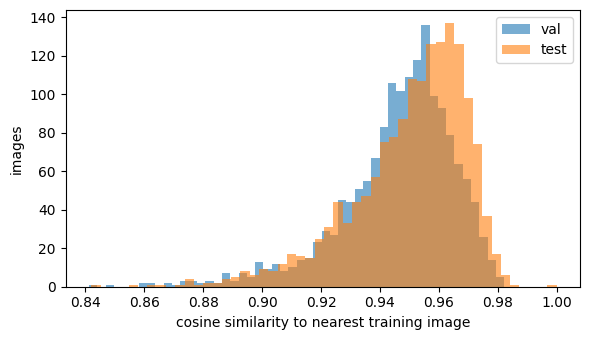

In [4]:
from scipy.stats import mannwhitneyu

train_emb, train_cls = emb[idx['train']], cls[idx['train']]
nn_rows, knn_rows = [], []
for split in ['val', 'test']:
    sim = emb[idx[split]] @ train_emb.T
    top = np.argpartition(-sim, K_NN, axis=1)[:, :K_NN]
    # Majority label among the K nearest training images
    votes = np.apply_along_axis(lambda r: np.bincount(r, minlength=4), 1, train_cls[top])
    knn_pred = votes.argmax(1)
    y = cls[idx[split]]
    nn_rows.append(pd.DataFrame({'split': split, 'class': np.array(CLASSES)[y], 'nn_cosine': sim.max(1)}))
    for k, c in enumerate(CLASSES):
        knn_rows.append({'split': split, 'class': c, 'knn_accuracy': (knn_pred[y == k] == k).mean()})
    knn_rows.append({'split': split, 'class': 'all', 'knn_accuracy': (knn_pred == y).mean()})

nn = pd.concat(nn_rows, ignore_index=True)
nn.to_csv(OUT_DIR / 'nearest_train_similarity.csv', index=False)

rows = []
for c in CLASSES + ['all']:
    v = nn[(nn['split'] == 'val') & ((nn['class'] == c) | (c == 'all'))]['nn_cosine']
    t = nn[(nn['split'] == 'test') & ((nn['class'] == c) | (c == 'all'))]['nn_cosine']
    u, p = mannwhitneyu(v, t)
    # Probability that a validation image is closer to the training set than a test image (0.5 = no difference)
    rows.append({'class': c, 'val_median': v.median(), 'test_median': t.median(),
                 'p_val_closer': u / (len(v) * len(t)), 'p_value': p})
sim_summary = pd.DataFrame(rows)
knn = pd.DataFrame(knn_rows).pivot(index='class', columns='split', values='knn_accuracy')[['val', 'test']]
knn['gap'] = knn['val'] - knn['test']

sim_summary.to_csv(OUT_DIR / 'similarity_summary.csv', index=False)
knn.to_csv(OUT_DIR / 'knn_accuracy.csv')
print('Nearest-neighbour cosine to the training set:')
print(sim_summary.round(4).to_string(index=False))
print(f'\n{K_NN}-NN accuracy with ImageNet embeddings:')
print(knn.round(4).to_string())

fig, ax = plt.subplots(figsize=(6, 3.5))
for split in ['val', 'test']:
    ax.hist(nn[nn['split'] == split]['nn_cosine'], bins=50, alpha=0.6, label=split)
ax.set_xlabel('cosine similarity to nearest training image'); ax.set_ylabel('images'); ax.legend()
plt.tight_layout(); plt.savefig(OUT_DIR / 'nearest_train_similarity.png', dpi=150); plt.show()

## 5. Can the splits be told apart?

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# A classifier that predicts the split from the embedding. AUC near 0.5 = the two splits look alike.
def split_auc(a, b):
    ids = np.r_[idx[a], idx[b]]
    y = np.r_[np.zeros(len(idx[a])), np.ones(len(idx[b]))]
    strata = y * 10 + cls[ids]  # keep split and class proportions in every fold
    clf = LogisticRegression(max_iter=3000, class_weight='balanced')
    p = cross_val_predict(clf, emb[ids], y, cv=list(StratifiedKFold(5, shuffle=True, random_state=0).split(ids, strata)),
                          method='predict_proba')[:, 1]
    row = {'pair': f'{a} vs {b}', 'auc_all': roc_auc_score(y, p)}
    for k, c in enumerate(CLASSES):
        m = cls[ids] == k
        row[f'auc_{c}'] = roc_auc_score(y[m], p[m])
    return row

auc = pd.DataFrame([split_auc('train', 'val'), split_auc('train', 'test'), split_auc('val', 'test')])
auc.to_csv(OUT_DIR / 'split_classifier_auc.csv', index=False)
print(auc.round(3).to_string(index=False))

         pair  auc_all  auc_defect  auc_longberry  auc_peaberry  auc_premium
 train vs val    0.802       0.775          0.792         0.827        0.818
train vs test    0.893       0.893          0.874         0.921        0.897
  val vs test    0.726       0.757          0.623         0.852        0.651


## 6. Color and brightness

In [6]:
def color_features(path):
    with Image.open(path) as img:
        rgb = np.asarray(img.convert('RGB'), dtype=np.float32) / 255
        hsv = np.asarray(img.convert('HSV'), dtype=np.float32) / 255
    gray = rgb @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    return {'red': rgb[..., 0].mean(), 'green': rgb[..., 1].mean(), 'blue': rgb[..., 2].mean(),
            'brightness': gray.mean(), 'contrast': gray.std(), 'saturation': hsv[..., 1].mean()}

feat = pd.DataFrame([color_features(LOCAL_DIR / i) for i in man['image_id']])
feat = pd.concat([man[['image_id', 'split', 'class']], feat], axis=1)
feat.to_csv(OUT_DIR / 'color_features.csv', index=False)
FEATURES = ['red', 'green', 'blue', 'brightness', 'contrast', 'saturation']

# Standardized mean difference (Cohen's d): |d| < 0.2 negligible, 0.5 medium, 0.8 large
def cohens_d(a, b):
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / pooled

rows = []
for c in CLASSES + ['all']:
    sub = feat if c == 'all' else feat[feat['class'] == c]
    for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
        row = {'class': c, 'pair': f'{a} vs {b}'}
        for f in FEATURES:
            row[f] = cohens_d(sub[sub['split'] == a][f], sub[sub['split'] == b][f])
        rows.append(row)
color_d = pd.DataFrame(rows)
color_d.to_csv(OUT_DIR / 'color_cohens_d.csv', index=False)

print('Mean per split and class:')
print(feat.groupby(['class', 'split'], sort=False)[FEATURES].mean().round(4).to_string())
print("\nCohen's d between splits:")
print(color_d.round(2).to_string(index=False))

Mean per split and class:
                    red   green    blue  brightness  contrast  saturation
class     split                                                          
defect    train  0.8349  0.8116  0.7756      0.8145    0.1715      0.1109
longberry train  0.8388  0.8169  0.7776      0.8190    0.1573      0.1051
peaberry  train  0.8414  0.8238  0.7967      0.8260    0.1744      0.0846
premium   train  0.8102  0.7898  0.7553      0.7920    0.1785      0.1071
defect    val    0.8788  0.8468  0.8036      0.8514    0.1632      0.1109
longberry val    0.8699  0.8350  0.7787      0.8390    0.1593      0.1303
peaberry  val    0.8589  0.8276  0.7879      0.8324    0.1789      0.1099
premium   val    0.8481  0.8160  0.7726      0.8207    0.1730      0.1169
defect    test   0.8810  0.8433  0.7928      0.8488    0.1617      0.1235
longberry test   0.8607  0.8191  0.7576      0.8246    0.1685      0.1454
peaberry  test   0.8686  0.8345  0.7954      0.8402    0.1697      0.1063
premium   te

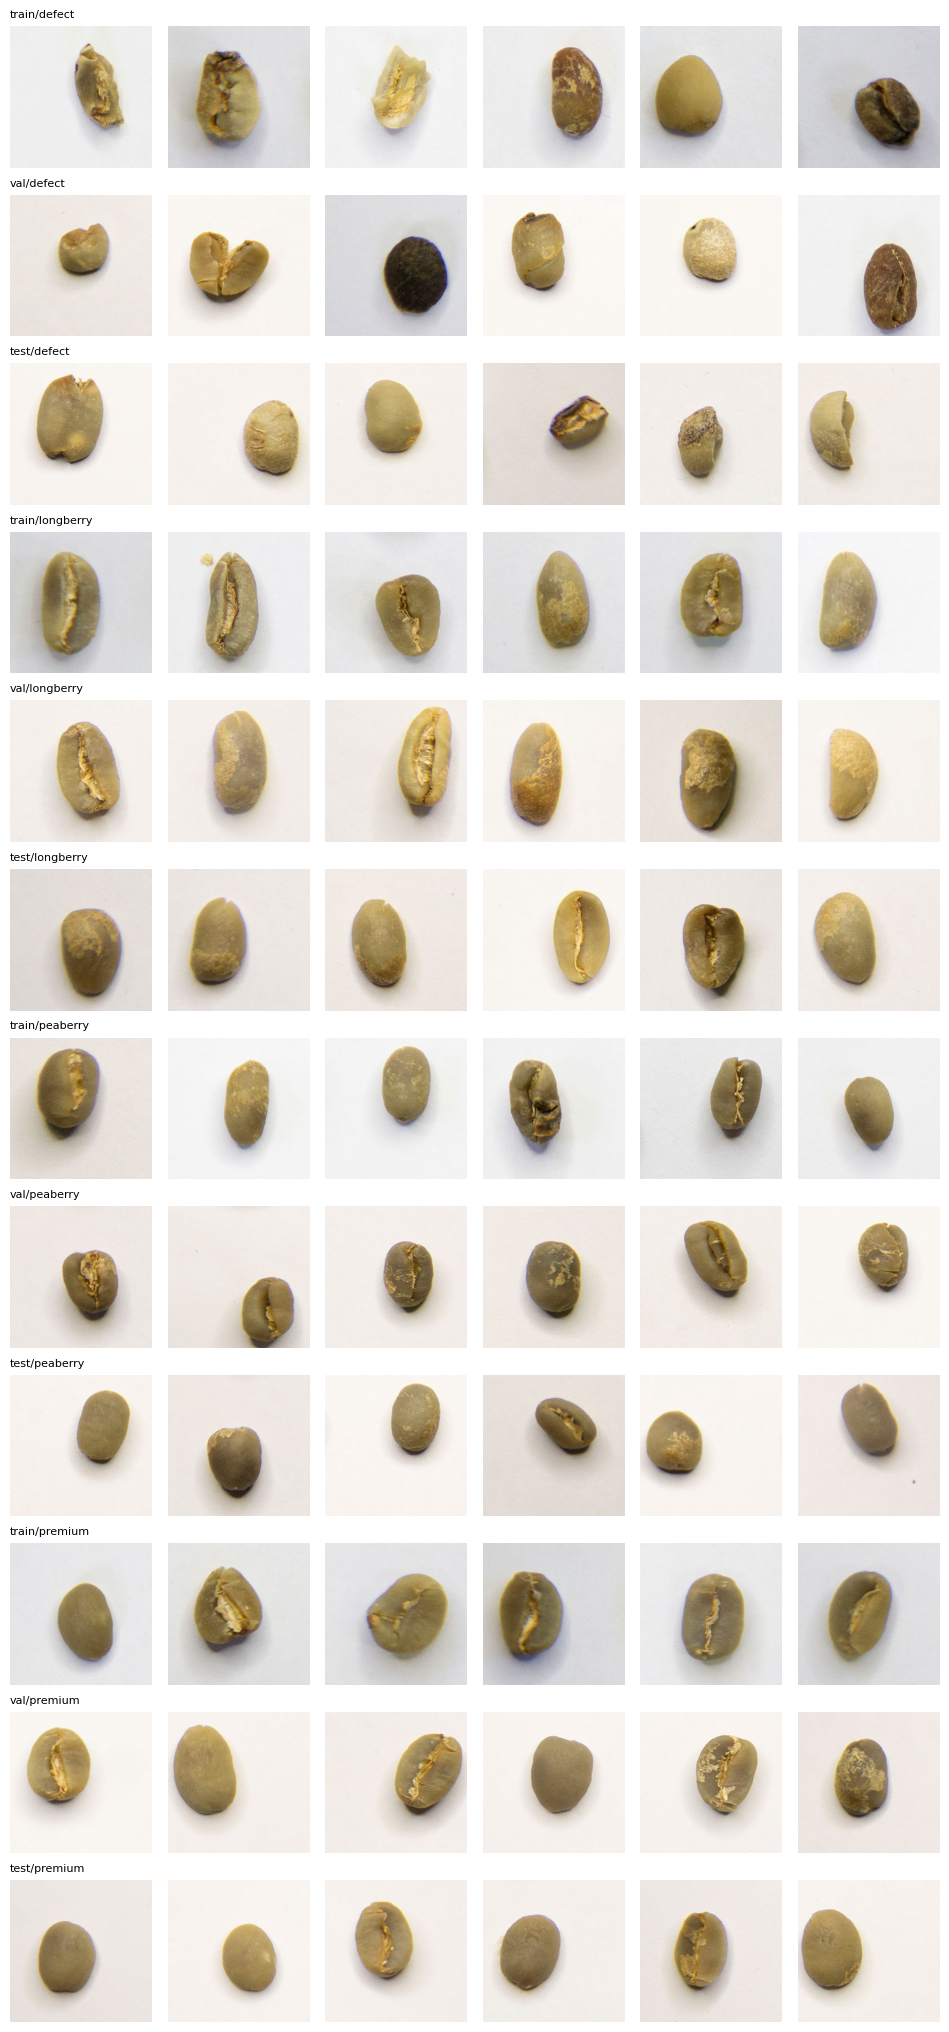

In [7]:
# Random examples per class, to compare the splits by eye
rng = np.random.default_rng(0)
n_show = 6
fig, axes = plt.subplots(len(CLASSES) * 3, n_show, figsize=(n_show * 1.6, len(CLASSES) * 3 * 1.7))
for r, (c, split) in enumerate([(c, s) for c in CLASSES for s in SPLITS]):
    ids = man[(man['class'] == c) & (man['split'] == split)]['image_id'].to_numpy()
    for j, i in enumerate(rng.choice(ids, n_show, replace=False)):
        with Image.open(LOCAL_DIR / i) as img:
            axes[r, j].imshow(img.convert('RGB'))
        axes[r, j].axis('off')
    axes[r, 0].set_title(f'{split}/{c}', fontsize=8, loc='left')
plt.tight_layout(); plt.savefig(OUT_DIR / 'examples_per_split.png', dpi=110); plt.show()

## 7. Validation and test recall per class

In [8]:
def load_preds(arch, scheme, seed, part):
    return np.load(MODEL_ROOT / arch / scheme / f'seed{seed}' / f'{part}_predictions.npz')

def hierarchical_predict(s1_prob, s2_prob):
    s1, s2 = s1_prob.argmax(1), s2_prob.argmax(1)
    return np.where(s1 == 2, 2 + s2, s1)

rows = []
for arch in ARCHS:
    for seed in SEEDS:
        for part in ['val', 'test']:
            flat, s1, s2 = (load_preds(arch, sc, seed, part) for sc in ['4class', '3class', '2class'])
            assert (flat['paths'] == s1['paths']).all() and (flat['paths'] == s2['paths']).all()
            y = flat['y_true']
            for model, pred in [('flat', flat['prob'].argmax(1)),
                                ('hierarchical', hierarchical_predict(s1['prob'], s2['prob']))]:
                for k, c in enumerate(CLASSES + ['all']):
                    m = np.ones_like(y, bool) if c == 'all' else (y == k)
                    rows.append({'arch': arch, 'model': model, 'seed': seed, 'split': part,
                                 'class': c, 'recall': (pred[m] == y[m]).mean()})

rec = pd.DataFrame(rows)
rec.to_csv(OUT_DIR / 'recall_val_test_per_seed.csv', index=False)
gap = rec.groupby(['arch', 'model', 'class', 'split'], sort=False)['recall'].mean().unstack('split')[['val', 'test']]
gap['gap'] = gap['val'] - gap['test']
gap.to_csv(OUT_DIR / 'recall_gap_per_class.csv')
print('Mean over three seeds ("all" = overall accuracy):')
print(gap.round(4).to_string())

Mean over three seeds ("all" = overall accuracy):
split                                      val    test     gap
arch            model        class                            
resnet50        flat         defect     0.8942  0.6900  0.2042
                             longberry  0.9683  0.8800  0.0883
                             peaberry   0.9658  0.7883  0.1775
                             premium    0.9783  0.9342  0.0442
                             all        0.9517  0.8231  0.1285
                hierarchical defect     0.9042  0.7467  0.1575
                             longberry  0.9592  0.8275  0.1317
                             peaberry   0.9833  0.8667  0.1167
                             premium    0.9633  0.9067  0.0567
                             all        0.9525  0.8369  0.1156
efficientnet_b0 flat         defect     0.8967  0.7392  0.1575
                             longberry  0.9783  0.9192  0.0592
                             peaberry   0.9633  0.7592  0.2042
     

## 8. Summary

In [9]:
summary = {
    'nn_cosine_median': {'val': float(sim_summary.iloc[-1]['val_median']),
                         'test': float(sim_summary.iloc[-1]['test_median'])},
    'p_val_closer_to_train': float(sim_summary.iloc[-1]['p_val_closer']),
    'knn_accuracy': {'val': float(knn.loc['all', 'val']), 'test': float(knn.loc['all', 'test'])},
    'split_classifier_auc': dict(zip(auc['pair'], auc['auc_all'].round(4))),
    'largest_color_d_val_vs_test': color_d[(color_d['pair'] == 'val vs test') & (color_d['class'] == 'all')]
        [FEATURES].abs().max().round(3).to_dict(),
    'recall_gap_mean_over_models': gap.groupby('class', sort=False)['gap'].mean().round(4).to_dict(),
}
with open(OUT_DIR / 'gap_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "nn_cosine_median": {
    "val": 0.949631929397583,
    "test": 0.954487144947052
  },
  "p_val_closer_to_train": 0.42773359375,
  "knn_accuracy": {
    "val": 0.70375,
    "test": 0.699375
  },
  "split_classifier_auc": {
    "train vs val": 0.8016,
    "train vs test": 0.8928,
    "val vs test": 0.7263
  },
  "largest_color_d_val_vs_test": {
    "red": 0.168,
    "green": 0.052,
    "blue": 0.042,
    "brightness": 0.076,
    "contrast": 0.066,
    "saturation": 0.297
  },
  "recall_gap_mean_over_models": {
    "defect": 0.1671,
    "longberry": 0.0879,
    "peaberry": 0.1562,
    "premium": 0.0379,
    "all": 0.1123
  }
}
